In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Exécuter le pipeline de pré-traitement
from sklearn.compose import ColumnTransformer
# on utilisera un pipeline pour enchaîner les traitements
from sklearn.pipeline import Pipeline
# les méthodes de prétraitement
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
# Train / Test
from sklearn.model_selection import train_test_split
# Entraîner un arbre de décision
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
# Entraîner une regression logistique
from sklearn.linear_model import LogisticRegression
# Entraîner un random forest
from sklearn.ensemble import RandomForestClassifier
# Arbre de décision
from sklearn.tree import plot_tree
# GridSearchCV : optimisation de F1
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#dataset = pd.read_csv("sample_data/ai4i2020_d.csv")
dataset = pd.read_csv("ai4i2020_d.csv")

In [ ]:
# Supprimer les colonnes inutiles pour prédire Survived
dataset = dataset.drop(columns=["UDI", "Product ID"], errors='ignore')

In [ ]:
dataset.isnull().sum()

,0
Type,0
Air temperature [K],2
Process temperature [K],1
Rotational speed [rpm],0
Torque [Nm],1
Tool wear [min],0
Machine failure,0


In [ ]:
dataset.describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
count,10001.000000,10002.000000,1.000300e+04,10002.000000,10003.000000,10003.000000
mean,330.069653,310.005119,1.671668e+03,39.985723,107.946816,0.033890
std,3006.650290,1.483844,1.333011e+04,9.967380,63.649417,0.180955
min,295.300000,305.700000,-1.898000e+03,3.800000,0.000000,0.000000
25%,298.300000,308.800000,1.423000e+03,33.200000,53.000000,0.000000
50%,300.100000,310.100000,1.503000e+03,40.100000,108.000000,0.000000
75%,301.500000,311.100000,1.612000e+03,46.700000,162.000000,0.000000
max,300980.000000,313.800000,1.334624e+06,76.600000,253.000000,1.000000


<Axes: >

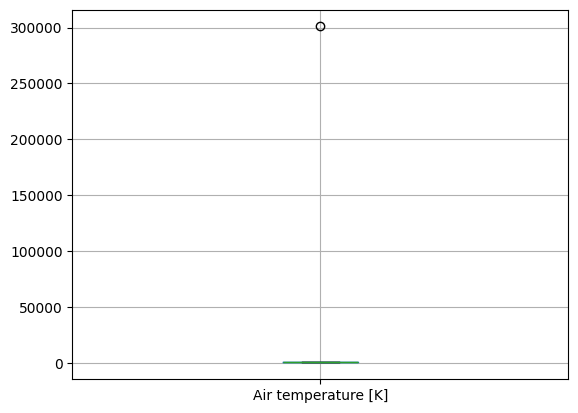

In [ ]:
dataset.boxplot(column="Air temperature [K]")

<Axes: >

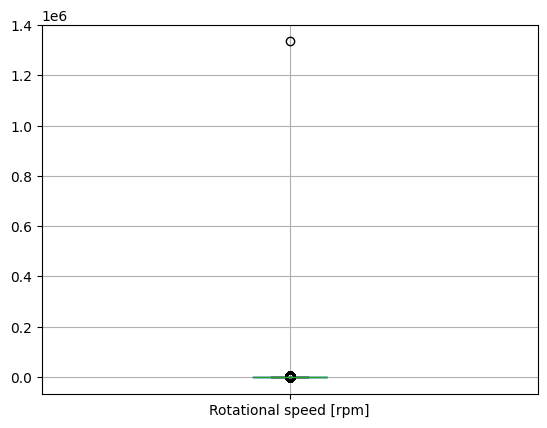

In [ ]:
dataset.boxplot(column="Rotational speed [rpm]")

**Feature selection**

In [ ]:
# Feature selection
# Colonnes numériques concernées
cols_to_fill = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Torque [Nm]"
]

# Remplacement des valeurs nulles par la moyenne
for col in cols_to_fill:
    mean_value = dataset[col].mean()
    dataset[col].fillna(mean_value, inplace=True)

# Vérification
dataset.isnull().sum()

/tmp/ipython-input-1746006734.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset[col].fillna(mean_value, inplace=True)


,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0


In [ ]:
# Calcul de la moyenne sans la valeur aberrante de "Air temperature"
mean_air_temp = dataset.loc[
    dataset["Air temperature [K]"] < 300000,
    "Air temperature [K]"
].mean()

# Remplacement de la valeur aberrante
dataset.loc[
    dataset["Air temperature [K]"] >= 300000,
    "Air temperature [K]"
] = mean_air_temp


In [ ]:
# Calcul de la moyenne sans la valeur aberrante de "Rotational speed"
mean_rotational = dataset.loc[
    dataset["Rotational speed [rpm]"] >= 0,
    "Rotational speed [rpm]"
].mean()

# Remplacement de la valeur aberrante
dataset.loc[
    dataset["Rotational speed [rpm]"] < 0,
    "Rotational speed [rpm]"
] = mean_rotational

/tmp/ipython-input-2875597785.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1672.0246950609878' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  dataset.loc[


In [ ]:
# Feature engineering
# Encodage des valeurs de Type
dataset["Type"] = dataset["Type"].map({
    "L": 0,
    "M": 1,
    "H": 2
})
dataset.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,1,298.1,308.6,1551.0,42.8,0,0
1,0,298.2,308.7,1408.0,46.3,3,0
2,0,298.1,308.5,1498.0,49.4,5,0
3,0,298.2,308.6,1433.0,39.5,7,0
4,0,298.2,308.7,1408.0,40.0,9,0


In [ ]:
dataset["Type"].unique()

array([1, 0, 2])

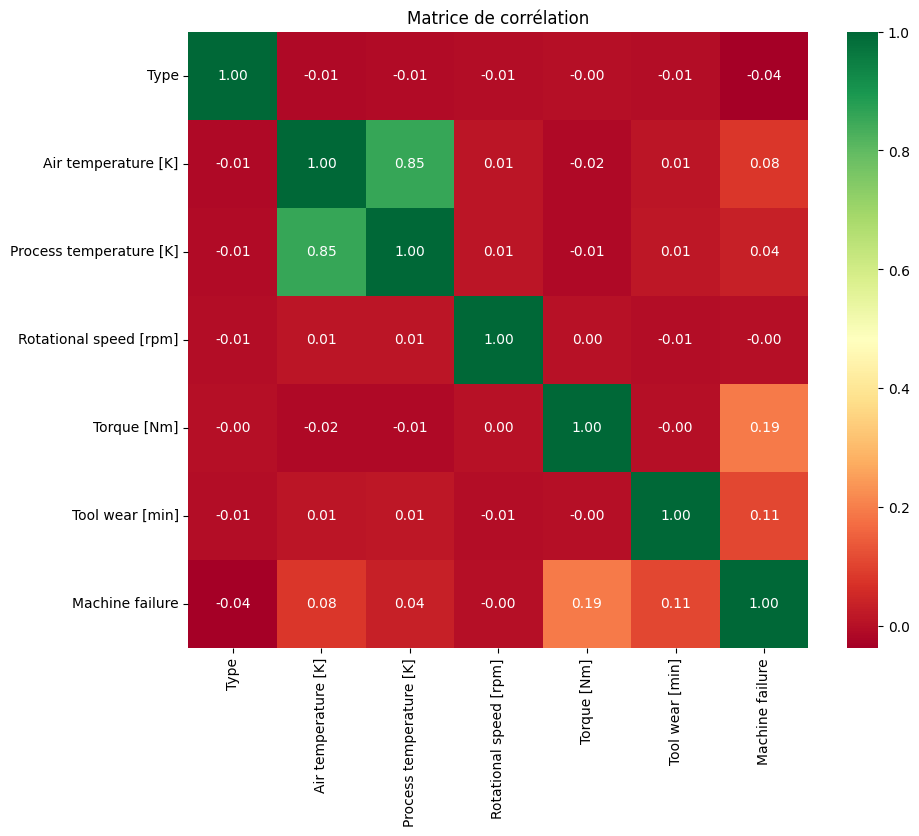

In [ ]:
# Corrélation

plt.figure(figsize=(10,8))
sns.heatmap(dataset.corr(),
            annot=True,
            cmap="RdYlGn",
            fmt=".2f")

plt.title("Matrice de corrélation")
plt.show()


**Début de la modélisation**

In [ ]:
# Train / test

x = dataset.drop("Machine failure", axis=1)
y = dataset["Machine failure"]

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y)

In [ ]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((8002, 6), (2001, 6), (8002,), (2001,))

In [ ]:
y.value_counts(normalize = True)

,proportion
Machine failure,
0,0.96611
1,0.03389


In [ ]:
y_train.value_counts(normalize = True)

,proportion
Machine failure,
0,0.966133
1,0.033867


In [ ]:
y_test.value_counts(normalize=True)

,proportion
Machine failure,
0,0.966017
1,0.033983


* Entraînement d'un arbre de décision

In [ ]:
# Modèle
modele_dt = DecisionTreeClassifier()
modele_dt.fit(x_train, y_train)

DecisionTreeClassifier()

In [ ]:
y_pred = modele_dt.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1933
           1       0.64      0.69      0.67        68

    accuracy                           0.98      2001
   macro avg       0.82      0.84      0.83      2001
weighted avg       0.98      0.98      0.98      2001



*   Regression logistique

In [ ]:
model_lr = LogisticRegression()
model_lr.fit(x_train, y_train)

LogisticRegression()

In [ ]:
y_pred_lr = model_lr.predict(x_test)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1933
           1       0.78      0.21      0.33        68

    accuracy                           0.97      2001
   macro avg       0.88      0.60      0.66      2001
weighted avg       0.97      0.97      0.96      2001




*   Random Forest

In [ ]:
model_rf = RandomForestClassifier()
model_rf.fit(x_train, y_train)

RandomForestClassifier()

In [ ]:
y_pred_rf = model_rf.predict(x_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1933
           1       0.90      0.68      0.77        68

    accuracy                           0.99      2001
   macro avg       0.95      0.84      0.88      2001
weighted avg       0.99      0.99      0.99      2001



Détermination du meilleur max_depth

In [ ]:
depths = range(1, 21)
best_depth = None
best_score = 0

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(x_train, y_train)

    y_pred = tree.predict(x_test)
    score = f1_score(y_test, y_pred)

    if score > best_score:
        best_score = score
        best_depth = d

print("Meilleur max_depth :", best_depth)


Meilleur max_depth : 11


**DecisionTree optimisé**

In [ ]:
tree_opt = DecisionTreeClassifier(max_depth=best_depth)
tree_opt.fit(x_train, y_train)

y_pred_tree_opt = tree_opt.predict(x_test)
print(classification_report(y_test, y_pred_tree_opt))


              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1933
           1       0.78      0.74      0.76        68

    accuracy                           0.98      2001
   macro avg       0.89      0.86      0.87      2001
weighted avg       0.98      0.98      0.98      2001



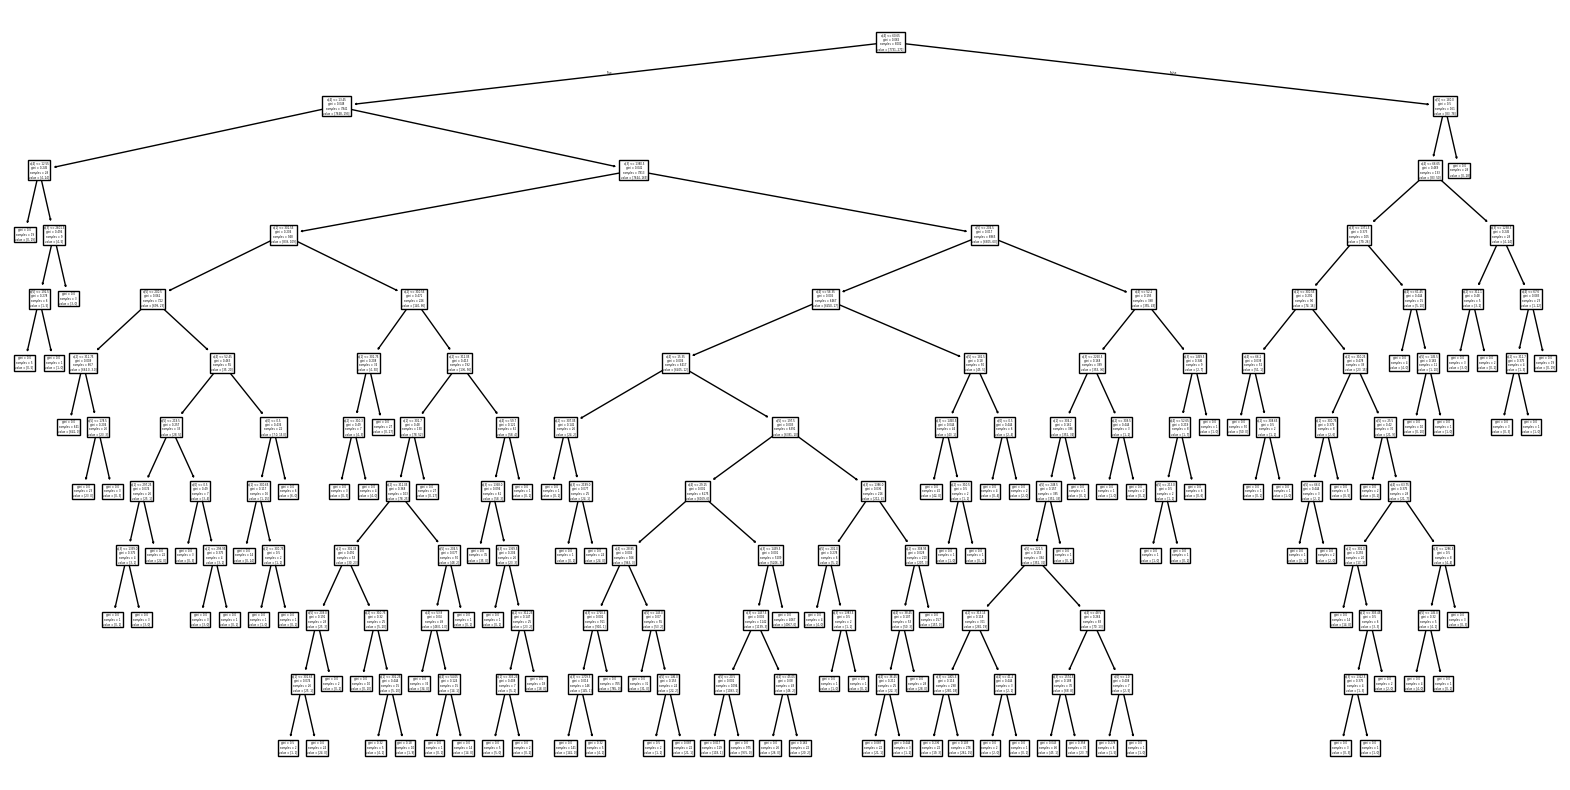

In [ ]:
plt.figure(figsize=(20,10))
plot_tree(tree_opt)

plt.show()


**Random Forest optimisé**

Implémentation du GridSearchCV

In [ ]:
# Définition de la grille
param_grid = {
    "n_estimators": [5, 10, 20, 50, 100],
    "max_depth": [2, 3, 5, 10, 15, None]
}
# Création du modèle
rf = RandomForestClassifier(random_state=42)
# GridSearchCV
grid = GridSearchCV(
    estimator=rf,
    param_grid = param_grid,
    scoring = "f1",
    cv = 5,
    n_jobs = -1
)

grid.fit(x_train, y_train)
print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur F1-score (CV) :", grid.best_score_)



Meilleurs paramètres : {'max_depth': 15, 'n_estimators': 100}
Meilleur F1-score (CV) : 0.6921366609104412


**Puissance du moteur**

In [ ]:
df = dataset
df["Power"] = df["Torque [Nm]"] * (2 * np.pi * df["Rotational speed [rpm]"] / 60)

X = df.drop("Machine failure", axis=1)
y = df["Machine failure"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [ ]:
param_grid = {
    'n_estimators': [5, 10, 20, 50, 100],
    'max_depth': [2, 3, 5, 10, 15, None]
}

rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(
    rf,
    param_grid,
    scoring = "f1",
    cv = 5,
    n_jobs = -1
)

grid.fit(X_train, y_train)


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [2, 3, 5, 10, 15, None],
                         'n_estimators': [5, 10, 20, 50, 100]},
             scoring='f1')

In [ ]:
best_rf = grid.best_estimator_

y_pred = best_rf.predict(X_test)
print(classification_report(y_test, y_pred))


NameError: name 'grid' is not defined